In [1]:
import os
import json
import yaml
import requests #for url downloading
import numpy as np
import matplotlib.pyplot as plt
import healpy as hp
import mhealpy as mhp
from astropy.io import fits
from astropy.coordinates import SkyCoord
from astropy import units as u
from astropy.table import QTable
import astropy_healpix as ah
from ligo.skymap.io.fits import read_sky_map
import ligo.skymap.plot #used impliciteely

import sys
sys.path.insert(1, '/Users/cristozilleruelo/Rubicube-Ampel-HU-astro/Rubicube/')
from params import p

import warnings #for import lal inside ligo.skymap
warnings.filterwarnings("ignore", "Wswiglal-redir-stdio")

def read_map(map_name, map_dir=p['map_dir']):
    '''
    Opens a map at map_path. If map_path is a url, it downloads the map in the save_dir folder
    '''

    #check if map_name is an url
    if 'https' in map_name:
        file_name = map_name.split('/')[-1]
        alert_name = file_name.split('_')[0]

        #first we download the map
        response = requests.get(map_name)
        map_path = os.path.join(map_dir, file_name)
        with open(map_path, 'wb') as file: #also deletes previously existing file and redownloads alert. 
            file.write(response.content)
    
    #if not url, then it could be a full path:
    elif os.path.exists(map_name):
        map_path = map_name
        alert_name = os.path.basename(map_path).split('_')[0]
    
    #Check if its just the filename:
    elif os.path.exists(os.path.join(map_dir, map_name)):
        map_path = os.path.join(map_dir, map_name)
        alert_name = os.path.basename(map_path).split('_')[0]
    
    #In case just the alert name like IceCube-260610A. We can check if this alert was already downloaded.
    #this will be usefull in case I want to pull up a specific alert on comand
    else:
        downloaded_maps = {alert.split('_')[0]: alert for alert in os.listdir(map_dir)}
        if map_name in downloaded_maps.keys():
            print('Opening downloaded alert: ', downloaded_maps[map_name])
            map_path = os.path.join(map_dir, downloaded_maps[map_name])
            alert_name = os.path.basename(map_path).split('_')[0]
        else:
            raise AttributeError(f'Incorrect Map name inpu: {map_name} \n. Please provide a url, map_path, or alert name in the format IceCube-YYMMDDA')


    #we open the map
    skymap = QTable.read(map_path)
    _, header = fits.getdata(map_path, header=True)

    #Check if array has masked values. We fill them with 0.0
    try:
        if skymap['PROBDENSITY'].mask.any():
            print("Map has masked values. reeplacing them with 0")
            skymap['PROBDENSITY'] = skymap['PROBDENSITY'].filled(0)
    except AttributeError:
        pass #array has no masked values

    map_data = {
        'skymap': skymap,
        'header': header,
        'map_path': map_path,
        'alert_name': alert_name
    }

    return map_data

def get_moc_map_metadata(skymap):
    '''
    Not sure if useful, but returns a dictionary with the metavalues for the multi-ordered map
    '''
    level, ipix = ah.uniq_to_level_ipix(skymap['UNIQ'])
    nside = ah.level_to_nside(level)
    pixel_area = ah.nside_to_pixel_area(nside)

    #we get ra and dec from maximum value of map
    arg_max = np.max(skymap['PROBDENSITY'])
    max_i = list(skymap['PROBDENSITY']).index(arg_max)
    max_ipix = ipix[max_i]
    ra, dec = hp.pix2ang(nside[max_i], max_ipix, lonlat=True, nest=True)
    ra = ra * u.deg
    dec = dec * u.deg
    
    metadata = {
        'PROBDENSITY': skymap['PROBDENSITY'],
        'UNIQ': skymap['UNIQ'],
        'LEVEL': level,
        'IPIX': ipix,
        'NSIDE': nside,
        'PIXELAREA': pixel_area,
        'RA': ra,
        'DEC': dec
    }

    return metadata

/Users/cristozilleruelo/.local/share/mamba/envs/AMPEL/lib/python3.14/site-packages/ligo/skymap/io/events/ligolw.py:26: UserWarning: Wswiglal-redir-stdio:

SWIGLAL standard output/error redirection is enabled in IPython.
This may lead to performance penalties. To disable locally, use:

with lal.no_swig_redirect_standard_output_error():
    ...

To disable globally, use:

lal.swig_redirect_standard_output_error(False)

Note however that this will likely lead to error messages from
LAL functions being either misdirected or lost when called from
Jupyter notebooks.

To suppress this warning, use:

import warnings
warnings.filterwarnings("ignore", "Wswiglal-redir-stdio")
import lal

  import lal


In [2]:
def plot_map(map_data, r=3, plot_prob_density=False, save_dir=p['save_dir'],
             coord='icrs', nest=True, show_fig=True, plot_ztf_lsst=True, plot_source=False,
             plot_only_zoomed_frame=False):
    
    #plotting info for ligo.skymap.plot
    ligo_coord = {
        'E': 'geo',
        'icrs': 'astro',
        'G': 'galactic'
    }
    astropy_frame = {
        'icrs': 'icrs',
        'G': 'galactic'
    }

    #get data and metadata
    skymap = map_data['skymap']
    header = map_data['header']
    alert_name = map_data['alert_name']
    metadata = get_moc_map_metadata(skymap)

    if not header:
        #we get ra and dec from maximum value of map
        arg_max = np.max(skymap['PROBDENSITY'])
        max_i = list(skymap['PROBDENSITY']).index(arg_max)
        max_ipix = metadata['IPIX'][max_i]
        ra, dec = hp.pix2ang(metadata['NSIDE'][max_i], max_ipix, lonlat=True, nest=True)
        ra = ra * u.deg
        dec = dec * u.deg

    else:
        header_dict = dict(header)
        ra = header_dict['RA'] * u.deg
        dec = header_dict['DEC'] * u.deg
    
    #zoom box center
    center = SkyCoord(ra.to('rad'), dec.to('rad'), frame=astropy_frame[coord])
    
    fig = plt.figure(figsize=(6, 6), dpi=100)

    ax = plt.axes(
        [0.05, 0.05, 0.8, 0.9],
        projection=f'{ligo_coord[coord]} degrees mollweide',
        center=SkyCoord(0 * u.rad, 0 * u.rad, frame=astropy_frame[coord]))
    ax_inset = plt.axes(
        [1.03, 0.3, 0.42, 0.42],
        projection=f'{ligo_coord[coord]} degrees zoom',
        center=center,
        radius=r * u.deg)
    
    if coord == 'icrs':
        for key in ['ra', 'dec']:
            ax_inset.coords[key].set_ticks_visible(False)
    
    ax_inset.set_xlabel("")
    ax_inset.set_ylabel("")
    ax.grid()
    ax.locator_params(nbins=10) #test!
    ax.mark_inset_axes(ax_inset)
    ax.connect_inset_axes(ax_inset, 'upper left')
    ax.connect_inset_axes(ax_inset, 'lower left')
    ax_inset.scalebar((0.1, 0.1), 1 * u.deg).label()
    ax_inset.compass(0.9, 0.1, 0.2)
    ax_inset.grid()
    ax.set_title(alert_name)
    ax_inset.set_title(fr'RA: {ra.value:.2f}$\degree$  DEC: {dec.value:.2f}$\degree$')


    #map processing
    if plot_prob_density:
        prob_density = skymap['PROBDENSITY'].to_value(u.deg**-2)

        m = mhp.HealpixMap(data=prob_density, uniq=skymap['UNIQ'], density=True)
        img = m.get_wcs_img(ax)#, coord = coord, rasterize = rasterize)
        ax.imshow(img, cmap='OrRd')
        img_inset = m.get_wcs_img(ax_inset)
        im = ax_inset.imshow(img_inset, cmap='OrRd')
        c = plt.colorbar(im, label=r'Prob density [$deg^{-2}$]')
    else:
        #we show absolute probability = prob_density * pixel_area
        prob = metadata['PIXELAREA'] * skymap['PROBDENSITY']

        m = mhp.HealpixMap(data=prob, uniq=skymap['UNIQ'], density=False)
        img = m.get_wcs_img(ax)#, coord = coord, rasterize = rasterize)
        ax.imshow(img, cmap='OrRd')
        img_inset = m.get_wcs_img(ax_inset)
        im = ax_inset.imshow(img_inset, cmap='OrRd')
        c = plt.colorbar(im, label=r'Probability')
    
    #get 90% and  50% confidence regions
    skymap.sort("PROBDENSITY", reverse=True)
    sorted_metadata = get_moc_map_metadata(skymap)
    prob = sorted_metadata['PIXELAREA'] * skymap["PROBDENSITY"]
    cumprob = np.cumsum(prob)
    # searchsorted gives the FIRST index where cumprob >= target.
    i_50 = cumprob.searchsorted(0.5)
    i_90 = cumprob.searchsorted(0.9)
    
    m_prob = mhp.HealpixMap(data=cumprob, uniq=skymap['UNIQ'], density=True)
    img = m_prob.get_wcs_img(ax_inset)#, coord = coord, rasterize = rasterize)
    im = ax_inset.contour(img, levels=[0.5, 0.9], colors=['black', 'black'], linestyles=['solid', 'dashed']) #nested=True,

    area_50 = sorted_metadata['PIXELAREA'][:i_50].sum().to(u.deg**2)
    area_90 = sorted_metadata['PIXELAREA'][:i_90].sum().to(u.deg**2)

    #area text
    props = dict(boxstyle='round', facecolor='wheat', alpha=0.5)
    text_str = f'Area 50%:\n {area_50:.3f} \n\nArea 90%:\n {area_90:.3f}'
    ax.text(1.9, 0.35, text_str, fontsize=14, bbox=props, transform=ax.transAxes)#, horizontalalignment='right', va='top')

    #extra plotting features
    if plot_ztf_lsst:
        lsst_limit =  [np.linspace(0,360, 50), np.ones(50) * 30]
        ztf_limit = [np.linspace(0,360, 50), np.ones(50) * -30]
        ax.plot(lsst_limit[0], lsst_limit[1], c='purple', linestyle='dotted', transform=ax.get_transform('world'))
        ax.plot(ztf_limit[0], ztf_limit[1], c='green', linestyle='dotted', transform=ax.get_transform('world'))

        ax_inset.plot(lsst_limit[0], lsst_limit[1], c='purple', linestyle='dotted', transform=ax_inset.get_transform('world'))
        ax_inset.plot(ztf_limit[0], ztf_limit[1], c='green', linestyle='dotted', transform=ax_inset.get_transform('world'))
        
        ax.text(175, 20, r'$\downarrow$LSST', c='purple', transform=ax.get_transform('world'))
        ax.text(175, -28, r'$\uparrow$ZTF', c='green', transform=ax.get_transform('world'))

    if isinstance(plot_source, dict):
        ax_inset.plot(plot_source['ra'],
                    plot_source['dec'], 'o',
                    label=plot_source['name'],
                    c='cyan',  
                    transform=ax_inset.get_transform('world'))    
        ax_inset.legend(framealpha=1)

    elif isinstance(plot_source, list):
        for source in plot_source:
            ax_inset.plot(source['ra'],
                        source['dec'], 'o',
                        label=source['name'],
                        transform=ax_inset.get_transform('world'))    
            ax_inset.legend(framealpha=1)

    if isinstance(save_dir, str):
        fig_path = os.path.join(save_dir, f'{alert_name}.png')
        plt.savefig(fig_path, bbox_inches='tight')
    if show_fig:
        plt.show()
        
    return fig_path, area_90, m

['IceCube-261020A']


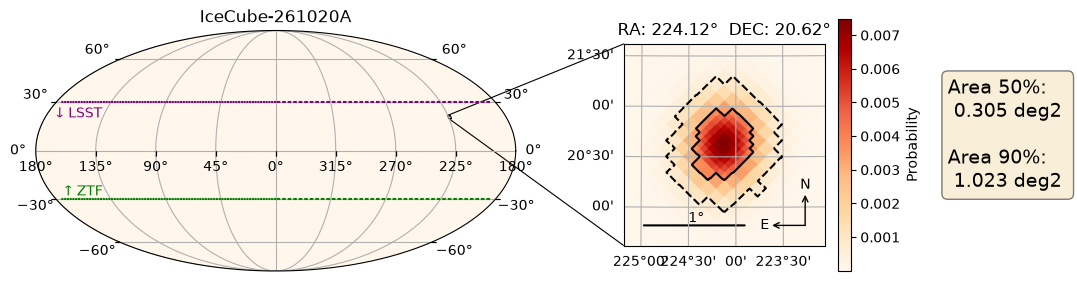

In [83]:
from hop import Stream
from hop.io import StartPosition
#https://hop-client.readthedocs.io/en/latest/user/quickstart.html

stream = Stream(start_at=StartPosition.EARLIEST, until_eos=True)
alerts = []
with stream.open("kafka://kafka.scimma.org/gcn.notices.icecube.gold_bronze_track_alerts", "r") as s:
    for message in s:
         # print(message.content)
        alerts.append(message.content)
alert = alerts[-1]
print(alert['event_name'])


map_data = read_map(alert['healpix_url'])
map_path, A_90, m = plot_map(map_data, r=1, plot_prob_density=False)


In [84]:
def plot_map_on_axis(healpix_map, ax, plot_ztf_lsst=True, clabel=''):
    '''
    Plots a map onto an axis 'ax' which already has mollwedie projection
    '''
    
    if plot_ztf_lsst:
        lsst_limit =  [np.linspace(0,360, 50), np.ones(50) * 30]
        ztf_limit = [np.linspace(0,360, 50), np.ones(50) * -30]
        ax.plot(lsst_limit[0], lsst_limit[1], c='purple', linestyle='dotted', transform=ax.get_transform('world'))
        ax.plot(ztf_limit[0], ztf_limit[1], c='green', linestyle='dotted', transform=ax.get_transform('world'))

    if isinstance(ax, ligo.skymap.plot.allsky.AstroDegreesMollweideAxes):
        ax.text(175, 20, r'$\downarrow$LSST', c='purple', transform=ax.get_transform('world'))
        ax.text(175, -28, r'$\uparrow$ZTF', c='green', transform=ax.get_transform('world'))
    img = healpix_map.get_wcs_img(ax)#, coord = coord, rasterize = rasterize)
    im = ax.imshow(img, cmap='OrRd')
    if isinstance(ax, ligo.skymap.plot.allsky.AstroDegreesZoomAxes):
        c = plt.colorbar(im, label=clabel)

def get_50_90_contour(skymap, ax):
    skymap.sort("PROBDENSITY", reverse=True)
    sorted_metadata = get_moc_map_metadata(skymap)
    prob = sorted_metadata['PIXELAREA'] * skymap["PROBDENSITY"]
    cumprob = np.cumsum(prob)
    # searchsorted gives the FIRST index where cumprob >= target.
    i_50 = cumprob.searchsorted(0.5)
    i_90 = cumprob.searchsorted(0.9)
    
    m_prob = mhp.HealpixMap(data=cumprob, uniq=skymap['UNIQ'], density=True)
    img = m_prob.get_wcs_img(ax)#, coord = coord, rasterize = rasterize)
    im = ax.contour(img, levels=[0.5, 0.9], colors=['black', 'black'], linestyles=['solid', 'dashed']) #nested=True,

    area_50 = sorted_metadata['PIXELAREA'][:i_50].sum().to(u.deg**2)
    area_90 = sorted_metadata['PIXELAREA'][:i_90].sum().to(u.deg**2)

    return area_50, area_90

def get_p_value_contour(skymap, ax, p):

    skymap.sort("PROBDENSITY", reverse=True)
    sorted_metadata = get_moc_map_metadata(skymap)
    prob = sorted_metadata['PIXELAREA'] * skymap["PROBDENSITY"]
    cumprob = np.cumsum(prob)

    # searchsorted gives the FIRST index where cumprob >= target.
    i_p = cumprob.searchsorted(p)
    
    
    m_prob = mhp.HealpixMap(data=cumprob, uniq=skymap['UNIQ'], density=True)
    img = m_prob.get_wcs_img(ax)#, coord = coord, rasterize = rasterize)
    im = ax.contour(img, levels=[p], colors=['cyan'], linestyles=['solid'], label=f'p = {p}') 
    # ax.legend(framealpha=1)

    area_p = sorted_metadata['PIXELAREA'][:i_p].sum().to(u.deg**2)
    
    return area_p


def plot_sources_on_ax(ax, plot_source):
        if isinstance(plot_source, dict):
            ax.plot(plot_source['ra'],
                        plot_source['dec'], 'o',
                        label=plot_source['name'],
                        c='cyan',  
                        transform=ax.get_transform('world'))    
            ax.legend(framealpha=1)
        
        elif isinstance(plot_source, list):
            for source in plot_source:
                ax.plot(source['ra'],
                            source['dec'], 'o',
                            label=source['name'],
                            transform=ax.get_transform('world'))    
                ax.legend(framealpha=1)
        return None

In [ ]:
def plot_full_map(map_data, r=3, plot_prob_density=False, save_dir=p['save_dir'],
             coord='icrs', nest=True, show_fig=True, plot_ztf_lsst=True, plot_source=False,
             plot_only_zoomed_frame=False, p_value=None):
    '''
     
    '''
    
    #plotting info for ligo.skymap.plot
    ligo_coord = {
        'E': 'geo',
        'icrs': 'astro',
        'G': 'galactic'
    }
    astropy_frame = {
        'icrs': 'icrs',
        'G': 'galactic'
    }

    #get data and metadata
    skymap = map_data['skymap']
    header = map_data['header']
    alert_name = map_data['alert_name']
    metadata = get_moc_map_metadata(skymap)
    ra, dec = metadata['RA'], metadata['DEC']


    #zoom box center
    center = SkyCoord(ra.to('rad'), dec.to('rad'), frame=astropy_frame[coord])
    
    fig = plt.figure(figsize=(6, 6), dpi=100)

    ax = plt.axes(
        [0.05, 0.05, 0.8, 0.9],
        projection=f'{ligo_coord[coord]} degrees mollweide',
        center=SkyCoord(0 * u.rad, 0 * u.rad, frame=astropy_frame[coord]))
    ax_inset = plt.axes(
        [1.03, 0.3, 0.42, 0.42],
        projection=f'{ligo_coord[coord]} degrees zoom',
        center=center,
        radius=r * u.deg)
    
    if coord == 'icrs':
        for key in ['ra', 'dec']:
            ax_inset.coords[key].set_ticks_visible(False)
    
    ax_inset.set_xlabel("")
    ax_inset.set_ylabel("")
    ax.grid()
    ax.locator_params(nbins=10) #test!
    ax.mark_inset_axes(ax_inset)
    ax.connect_inset_axes(ax_inset, 'upper left')
    ax.connect_inset_axes(ax_inset, 'lower left')
    ax_inset.scalebar((0.1, 0.1), 1 * u.deg).label()
    ax_inset.compass(0.9, 0.1, 0.2)
    ax_inset.grid()
    ax.set_title(alert_name)
    ax_inset.set_title(fr'RA: {ra.value:.2f}$\degree$  DEC: {dec.value:.2f}$\degree$')


    #map processing
    if plot_prob_density:
        prob_density = skymap['PROBDENSITY'].to_value(u.deg**-2)
        m = mhp.HealpixMap(data=prob_density, uniq=skymap['UNIQ'], density=True)
        clabel = r'Prob density [$deg^{-2}$]'
    else:
        #we show absolute probability = prob_density * pixel_area
        prob = metadata['PIXELAREA'] * skymap['PROBDENSITY']
        m = mhp.HealpixMap(data=prob, uniq=skymap['UNIQ'], density=False)
        clabel = 'Absolute Probability'

    plot_map_on_axis(m, ax, plot_ztf_lsst=plot_ztf_lsst)
    plot_map_on_axis(m, ax_inset, plot_ztf_lsst=plot_ztf_lsst, clabel=clabel)

    _ = get_50_90_contour(skymap, ax)
    area_50, area_90 = get_50_90_contour(skymap, ax_inset)

    #get our own p_value search
    if p_value is not None:
        get_p_value_contour(skymap, ax_inset, p_value)
    

    #area text
    props = dict(boxstyle='round', facecolor='wheat', alpha=0.5)
    text_str = f'Area 50%:\n {area_50:.3f} \n\nArea 90%:\n {area_90:.3f}'
    ax.text(1.9, 0.35, text_str, fontsize=14, bbox=props, transform=ax.transAxes)#, horizontalalignment='right', va='top')

    plot_sources_on_ax(ax_inset, plot_source)
        

    if isinstance(save_dir, str):
        fig_path = os.path.join(save_dir, f'{alert_name}.png')
        plt.savefig(fig_path, bbox_inches='tight')
    if show_fig:
        plt.show()
        
    return fig_path, area_90, m

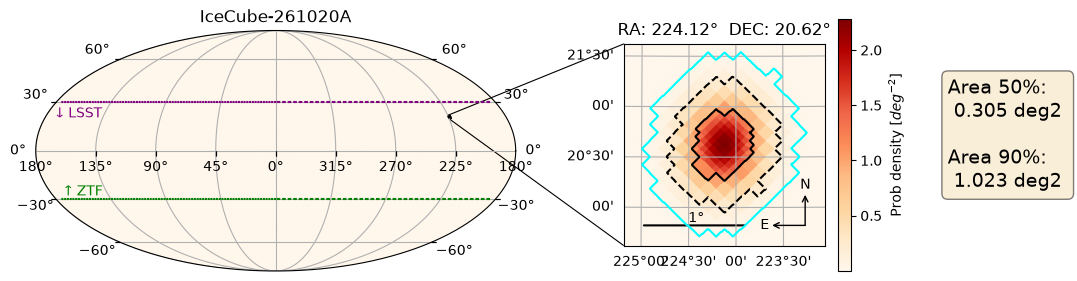

In [86]:
map_data = read_map(alert['healpix_url'])
map_path, A_90, m = plot_full_map(map_data, r=1, plot_prob_density=True, p_value=0.99)


### Zoomed alert function

In [ ]:
from matplotlib.colors import ListedColormap
def plot_selected_regions(ax, hpx_regions):
    '''
    Used for debug, shows the selected pixels in the query
    '''
    for level in hpx_regions:
        nside = level['nside']
        pixels = level['pixels']

        for pixel in pixels:
            data = np.zeros(hp.nside2npix(nside))
            data[pixel] += 1

            healpix_map = mhp.HealpixMap(data=data, nside=nside, scheme='NESTED')

            img = healpix_map.get_wcs_img(ax)#, coord = coord, rasterize = rasterize)

            #in a boolean map of values 0 or 1, level=0.5 is identified when the map sharply passes from 0 to 1, which works for outlining the pixels
            im = ax.contour(img, levels=[0.5], colors=['green'], linestyles=['solid']) #nested=True,
    
        
    return None
def deres(healpix_regions):
    """
    Addition by Cris Z:
    An adaptation of the deres function from AmpelHealpix.py that now works for multi-ordered maps.
    
    Compresses a list of HEALPix regions into the coarsest possible resolution 
    by recursively merging groups of 4 sibling pixels into their parent.
    
    Parameters:
    -----------
    healpix_regions : list of dicts
        Format: [{'nside': 1024, 'pixels': [...]}, {'nside': 512, 'pixels': [...]}]
        
    Returns:
    --------
    list of dicts
        The minimized and coarsened pixel regions.
    """
    # 1. Group all input pixels into sets mapped by their hierarchical order (order = log2(nside))
    pixel_sets = {}
    for region in healpix_regions:
        nside = region['nside']
        pixels = region['pixels']
        order = int(np.round(np.log2(nside)))
        if order not in pixel_sets:
        # Using a set allows fast membership checks and removal during merging
            pixel_sets[order] = set()
        pixel_sets[order].update(pixels)
        
    # 2. Iteratively merge from fine (high order) to coarse (low order) 
    # until no more groups of 4 siblings can be combined.
    changed = True
    while changed:
        changed = False
        orders = sorted(pixel_sets.keys(), reverse=True)
        
        for order in orders:
            if order <= 0:
                continue
            current_pixels = pixel_sets.get(order, set())
            if not current_pixels:
                continue
                
            # Map parent pixel indices to their set of present children (0, 1, 2, or 3)
            parent_dict = {}
            for pix in current_pixels:
                parent = pix // 4
                remainder = pix % 4
                if parent not in parent_dict:
                    parent_dict[parent] = set()
                parent_dict[parent].add(remainder)
                
            # Find parents that have all 4 children present ({0, 1, 2, 3})
            parents_to_promote = [p for p, children in parent_dict.items() if children == {0, 1, 2, 3}]
            
            if parents_to_promote:
                # Remove the 4 children from the current finer order
                for parent in parents_to_promote:
                    for i in range(4):
                        current_pixels.remove(4 * parent + i)
                        
                # Add the parent to the next coarser order (order - 1)
                lower_order = order - 1
                if lower_order not in pixel_sets:
                    pixel_sets[lower_order] = set()
                pixel_sets[lower_order].update(parents_to_promote)
                
                # Flag that a merge occurred so the loop runs again 
                # (allowing newly formed parents to cascade upward if possible)
                changed = True
                
    # 3. Format the result back into your original list-of-dicts structure
    compressed_regions = []
    for order in sorted(pixel_sets.keys()):
        if pixel_sets[order]:
            compressed_regions.append({
                'nside': int(2**order),
                'pixels': sorted(list(pixel_sets[order]))
            })
            
    return compressed_regions


In [ ]:
def plot_zoomed_IC_alert(map_data, r=3, plot_prob_density=False, save_dir=p['save_dir'],
             coord='icrs', show_fig=True, plot_ztf_lsst=True, plot_source=False,
             plot_only_zoomed_frame=False, p_value=None, debug=None):
    '''
    '''
    #plotting info
    ligo_coord = {
        'E': 'geo',
        'icrs': 'astro',
        'G': 'galactic'
    }
    astropy_frame = {
        'icrs': 'icrs',
        'G': 'galactic'
    }
    
    #get data and metadata
    skymap = map_data['skymap']
    header = map_data['header']
    alert_name = map_data['alert_name']
    metadata = get_moc_map_metadata(skymap)
    ra, dec = metadata['RA'], metadata['DEC']


    #zoom box center
    center = SkyCoord(ra.to('rad'), dec.to('rad'), frame=astropy_frame[coord])
    
    fig = plt.figure(figsize=(6, 6), dpi=100)


    ax = plt.axes(
        [0.05, 0.05, 0.8, 0.9],
        projection=f'{ligo_coord[coord]} degrees zoom',
        center=center,
        radius=r * u.deg)
    
    if coord == 'icrs':
        for key in ['ra', 'dec']:
            # ax_inset.coords[key].set_ticklabel_visible(False)
            ax.coords[key].set_ticks_visible(False)
    ax.set_xlabel("RA")
    ax.set_ylabel("DEC")
    ax.grid()    

    #map processing
    if plot_prob_density:
        prob_density = skymap['PROBDENSITY'].to_value(u.deg**-2)
        m = mhp.HealpixMap(data=prob_density, uniq=skymap['UNIQ'], density=True)
        clabel = r'Prob density [$deg^{-2}$]'
    else:
        #we show absolute probability = prob_density * pixel_area
        prob = metadata['PIXELAREA'] * skymap['PROBDENSITY']
        m = mhp.HealpixMap(data=prob, uniq=skymap['UNIQ'], density=False)
        clabel = 'Absolute Probability'

    plot_map_on_axis(m, ax, plot_ztf_lsst=plot_ztf_lsst, clabel=clabel)
    area_50, area_90 = get_50_90_contour(skymap, ax)

    #get our own p_value search
    if p_value is not None:
        get_p_value_contour(skymap, ax, p_value)

    plot_sources_on_ax(ax, plot_source)


    if type(debug) == list:
        plot_selected_regions(ax, debug)
       
    
    ra_title = ra / u.deg
    dec_title = dec / u.deg
    ax.set_title(fr'RA: {ra_title:.2f}$\degree$  DEC: {dec_title:.2f}$\degree$')
    pos = ax.get_position()
    plt.suptitle(alert_name, x=pos.x0 + pos.width / 2.0, y=0.9)
    # plt.suptitle(alert_name)
    if save_dir:
        plt.savefig(os.path.join(save_dir, f'{alert_name}_mw_zoom.png'), bbox_inches='tight')
    if show_fig:
        plt.show()
    
    if type(debug) == list:
        return map_path#, sel_pixels_lon, sel_pixels_lat
    return map_path

In [93]:
ra, dec = [177.71, 8.95]
nside=1024

theta = np.deg2rad(90 - dec)
phi = np.deg2rad(ra)

sample_pix = hp.ang2pix(nside, theta, phi, nest = True)
print(sample_pix)

hpx_regions = [{'nside': nside, 'pixels': [sample_pix]}]


7115603


In [124]:
hpx_regions_09 = [{'nside': 1024, 'pixels': [2294416, 2294330, 2294417, 2294418, 2294405, 2294419, 2294319, 2294331, 2294407, 2294328, 2294424, 2294420, 2294317, 2294425, 2294422, 2294404, 2294318, 2294329, 2294334, 2294413, 2294428, 2294406, 2294316, 2294322, 2294311, 2294427, 2294426, 2294332, 2294423, 2294421, 2294315, 2294323, 2294412, 2294401, 2294310, 2294430, 2294429, 2294415, 2294335, 2294313, 2294403, 2294309, 2294326, 2294320, 2294431, 2294449, 2294307, 2294333, 2294448, 2294414, 2294466, 2294308, 2294452, 2294409, 2294464, 2294321, 2294314, 2294472, 2294400, 2294437, 2294312, 2294378, 2294453, 2294305, 2294402, 2294474, 2294327, 2294306, 2294324, 2294411, 2294451, 2294436, 2294376, 2294450, 2294454, 2294408, 2294467, 2294465, 2294473, 2294304, 2294439, 2294455, 2294325, 2294379, 2294475, 2294410, 2294438, 2294377]}, {'nside': 512, 'pixels': [573571, 573574, 562655, 573624, 573570, 562677, 573592, 562653, 573608, 573575, 573614, 573615, 573617, 573619, 562679, 573611, 573595, 573569, 562647, 573626, 573572, 573625, 573568, 573586, 562654, 562685, 573610, 573593, 562676, 562652, 573573, 573956, 573957, 573627, 562645, 573622, 573620, 562678, 562646, 573953, 573968, 573483, 573628, 573598, 573486, 573584, 573482, 573587, 562687, 573969, 573952, 562684, 562644, 573630, 562651, 573487]}]
hpx_regions_099 = [{'nside': 1024, 'pixels': [2294416, 2294330, 2294417, 2294418, 2294405, 2294419, 2294319, 2294331, 2294407, 2294328, 2294424, 2294420, 2294317, 2294425, 2294422, 2294404, 2294318, 2294329, 2294334, 2294413, 2294428, 2294406, 2294316, 2294322, 2294311, 2294427, 2294426, 2294332, 2294423, 2294421, 2294315, 2294323, 2294412, 2294401, 2294310, 2294430, 2294429, 2294415, 2294335, 2294313, 2294403, 2294309, 2294326, 2294320, 2294431, 2294449, 2294307, 2294333, 2294448, 2294414, 2294466, 2294308, 2294452, 2294409, 2294464, 2294321, 2294314, 2294472, 2294400, 2294437, 2294312, 2294378, 2294453, 2294305, 2294402, 2294474, 2294327, 2294306, 2294324, 2294411, 2294451, 2294436, 2294376, 2294450, 2294454, 2294408, 2294467, 2294465, 2294473, 2294304, 2294439, 2294455, 2294325, 2294379, 2294475, 2294410, 2294438, 2294377]}, {'nside': 512, 'pixels': [573571, 573574, 562655, 573624, 573570, 562677, 573592, 562653, 573608, 573575, 573614, 573615, 573617, 573619, 562679, 573611, 573595, 573569, 562647, 573626, 573572, 573625, 573568, 573586, 562654, 562685, 573610, 573593, 562676, 562652, 573573, 573956, 573957, 573627, 562645, 573622, 573620, 562678, 562646, 573953, 573968, 573483, 573628, 573598, 573486, 573584, 573482, 573587, 562687, 573969, 573952, 562684, 562644, 573630, 562651, 573487, 562559, 573596, 562649, 573959, 562673, 573958, 573970, 562643, 573623, 573955, 573585, 562675, 573621, 573972, 573629, 573481, 563029, 573498, 562686, 562558, 573590, 573480, 573971, 573484, 573599, 562641, 573631, 573954, 562557, 562681, 573485, 573597, 562650, 562648, 573965, 573964, 573974, 562672, 573976, 573499, 562555, 562642, 573588, 573973, 563028, 562556, 573961, 563031, 573666, 562683, 562674, 573496, 573977, 573664, 573672, 573475, 573474, 573591, 562640, 573478, 573642, 573674, 562551, 573960, 573975, 562553, 562680, 573980, 573479, 573502, 562554, 573967, 573640, 573497, 574016, 563030, 562550]}]

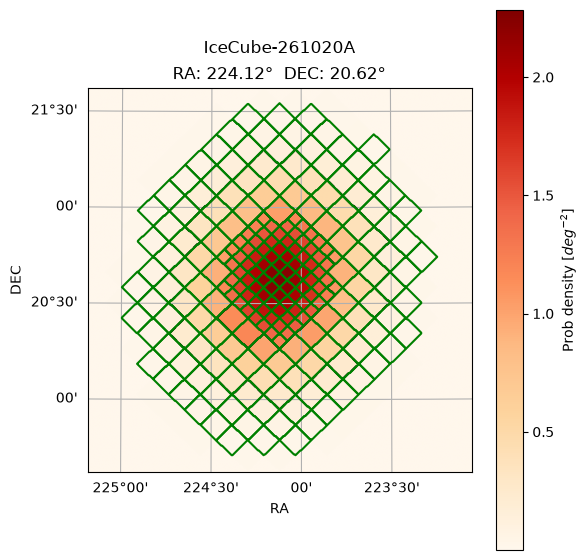

'/Users/cristozilleruelo/Rubicube-Ampel-HU-astro/RubiCube/plots/IceCube-261020A.png'

In [105]:
plot_zoomed_IC_alert(map_data, r=1, plot_prob_density=True,  debug=hpx_regions_099)

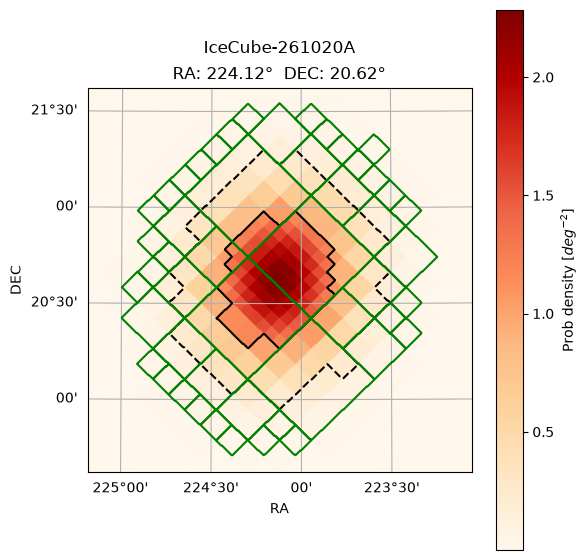

'/Users/cristozilleruelo/Rubicube-Ampel-HU-astro/RubiCube/plots/IceCube-261020A.png'

In [106]:
plot_zoomed_IC_alert(map_data, r=1, plot_prob_density=True,  debug=deres(hpx_regions_099))

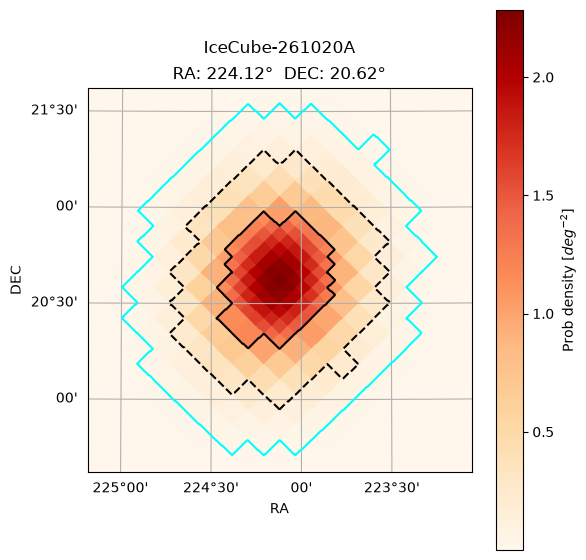

'/Users/cristozilleruelo/Rubicube-Ampel-HU-astro/RubiCube/plots/IceCube-261020A.png'

In [108]:
plot_zoomed_IC_alert(map_data, r=1, plot_prob_density=True,  p_value=0.99)

### Now lets test the AmpelHealpix deres function

In [114]:
import sys
sys.path.insert(1, '/Users/cristozilleruelo/Rubicube-Ampel-HU-astro/')
from ampel.contrib.hu.util.AmpelHealpix import deres

In [116]:
help(deres)

Help on function deres in module ampel.contrib.hu.util.AmpelHealpix:

deres(nside, ipix, min_nside=1)
    Decompose a set of (nested) HEALpix indices into sets of complete superpixels at lower resolutions.
    :param nside: nside of given indices
    :param ipix: pixel indices
    :min_nside: minimum nside of complete pixels

    Copied from Ampel-ZTF-archive.



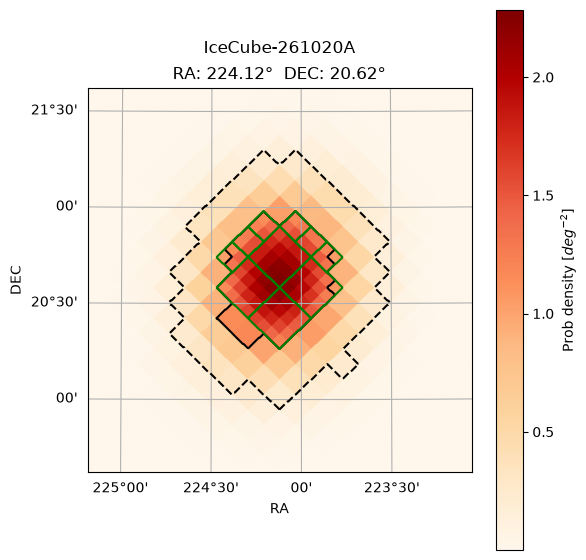

'/Users/cristozilleruelo/Rubicube-Ampel-HU-astro/RubiCube/plots/IceCube-261020A.png'

In [122]:
test_hpx_regions = [{'nside': 1024, 'pixels': [2294416, 2294330, 2294417, 2294418, 2294405, 2294419, 2294319, 2294331, 2294407, 2294328, 2294424, 2294420, 2294317, 2294425, 2294422, 2294404, 2294318, 2294329, 2294334, 2294413, 2294428, 2294406, 2294316, 2294322, 2294311, 2294427, 2294426, 2294332, 2294423, 2294421, 2294315, 2294323, 2294412, 2294401, 2294310, 2294430, 2294429, 2294415, 2294335, 2294313, 2294403, 2294309, 2294326, 2294320, 2294431, 2294449, 2294307, 2294333, 2294448, 2294414, 2294466, 2294308, 2294452, 2294409, 2294464, 2294321, 2294314, 2294472, 2294400, 2294437, 2294312, 2294378, 2294453, 2294305, 2294402, 2294474, 2294327, 2294306, 2294324, 2294411, 2294451, 2294436, 2294376, 2294450, 2294454, 2294408, 2294467, 2294465, 2294473, 2294304, 2294439, 2294455, 2294325, 2294379, 2294475, 2294410, 2294438, 2294377]}]
deres_output = deres(1024, test_hpx_regions[0]['pixels'])
sel_pixels = list()
for nside in deres_output.keys():
    sel_pixels.append({'nside': nside,
                  'pixels': deres_output[nside]})

plot_zoomed_IC_alert(map_data, r=1, plot_prob_density=True,  debug=sel_pixels)

In [134]:
total_pixels = dict()
for level in hpx_regions_099:
    print('\n', level['nside'])

    deres_output = deres(level['nside'], level['pixels'])

    print('Deres output: ', deres_output)


    for key in deres_output.keys():
        if key not in total_pixels: 
            total_pixels[key] = deres_output[key]
        else:
            total_pixels[key].extend(deres_output[key])

    #check if there are repeated numbers
    for key in total_pixels.keys():
        print(len(set(total_pixels[key])) == len(total_pixels[key]))
    
print('\n final dict: ', total_pixels)
    


 1024
Deres output:  {256: [143394, 143395, 143400, 143401], 512: [573594, 573609, 573612, 573613, 573616, 573618]}
True
True

 512
Deres output:  {128: [35165], 256: [143488, 143489, 143492, 143493, 143370, 143371, 143374, 143392, 143393, 143396, 143399, 143405, 143406, 143407, 140757, 140639, 140668, 140669, 140671], 512: [573960, 573961, 573964, 573965, 573967, 573976, 573977, 573980, 573474, 573475, 573478, 573479, 573502, 574016, 573588, 573590, 573591, 573592, 573593, 573595, 573608, 573610, 573611, 573614, 573615, 573617, 573619, 573640, 573642, 573664, 573666, 573672, 573674, 562550, 562551, 562553, 562554, 562555, 562680, 562681, 562683]}
True
True
True

 final dict:  {256: [143394, 143395, 143400, 143401, 143488, 143489, 143492, 143493, 143370, 143371, 143374, 143392, 143393, 143396, 143399, 143405, 143406, 143407, 140757, 140639, 140668, 140669, 140671], 512: [573594, 573609, 573612, 573613, 573616, 573618, 573960, 573961, 573964, 573965, 573967, 573976, 573977, 573980, 573

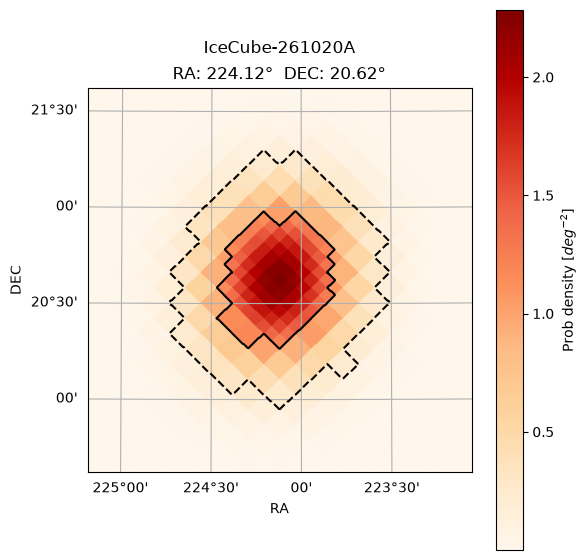

'/Users/cristozilleruelo/Rubicube-Ampel-HU-astro/RubiCube/plots/IceCube-261020A.png'

In [135]:
plot_zoomed_IC_alert(map_data, r=1, plot_prob_density=True,  debug=total_pixels)